# Linear Regression with Adagrad (Adaptive Gradient Algorithm)

This notebook demonstrates how to perform linear regression using the Adagrad optimization algorithm on synthetic data. We'll walk through each part of the code step-by-step to understand the concepts involved.

#### **Import Required Libraries**

- **NumPy** is used for numerical operations and handling arrays.
- **Matplotlib** is for plotting graphs to visualize results.
- **TQDM** provides a progress bar for loops.
- **Scikit-learn** is used for calculating the R² score, which evaluates our model.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

pbar_format = "{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]"

## 1. Helper Function

### Generate Synthetic Data

We create a function to generate synthetic data that follows a linear relationship.

- **Parameters**:
  - `n`: Number of data points.
  - `bias`: Intercept of the line.
  - `weight`: Slope of the line.
- **Output**: An array containing features and labels.

In [ ]:
def synthetic_data(n=100, bias=5, weight=2):

    np.random.seed(42)
    torch.manual_seed(42)
    # Generate synthetic data (linear relationship with some noise)
    bias = 5
    weight = 2
    noise = np.random.randn(n)

    features = np.random.rand(n, 1) * 10
    labels = bias + weight * features.flatten() + noise # Linear relation with noise

    data = np.hstack((features, labels.reshape(-1, 1)))
    return data

### Visualizing Results

This function will create plots for:
- Loss over epochs
- Values of model parameters (weights)

In [ ]:
def plot_results(history, cost_history, lr, fontsize=10, markersize=8):

    history = np.array(history)

    # Create subplots: 3 rows, 1 column
    fig, axs = plt.subplots(history.shape[1] + 1, 1, figsize=(12, 15)) # Adjusted number of rows

    # Plot the loss over epochs
    axs[0].plot(range(len(cost_history)), cost_history, '*-b', markersize=markersize, label='Loss per Epoch')
    axs[0].set_title(f'Loss per Epoch for lr={lr}', fontsize=16, fontweight='bold')
    axs[0].set_xlabel('Iteration', fontsize=fontsize)
    axs[0].set_ylabel('Loss', fontsize=fontsize)
    axs[0].legend()
    axs[0].grid(True)

    # Plot the values of each theta over iterations
    for i in range(history.shape[1]):
        axs[i + 1].plot(history[:, i], '-m.', markersize=markersize, label=f'Theta {i}')
        axs[i + 1].set_title(f'Theta {i} Values over Iterations for lr={lr}', fontsize=fontsize + 4, fontweight='bold')
        axs[i + 1].set_ylabel(f'Theta {i} Value', fontsize=fontsize)
        axs[i + 1].set_xlabel('Iteration', fontsize=fontsize)
        axs[i + 1].grid(True)

    # Adjust layout to prevent overlap
    plt.tight_layout()
    plt.show()

### Evaluate the Model

We define a function to evaluate the model's performance using the R² score:

In [ ]:
from sklearn.metrics import r2_score

def evaluate_model(X, y, theta):
    predictions = X @ theta
    return r2_score(y, predictions)

### (optional) Use Decorators to Display Pretty Report after Training

In [ ]:
def report_decorator(func):
    def wrapper(*args, **kwargs):

        result = func(*args, **kwargs)
        epoch, weights_history, cost_history, r2 = result

        print("="*60)
        print(" "*20, "Final Training Report")
        print("="*60)
        print(f"🟢 Total Epochs Run : {epoch+1}")
        print(f"🟢 Final MSE        : {cost_history[-1]:.3f}")
        print(f"🟢 Final R-square   : {r2:.3f}")
        print(f"🟢 Final Weights    : [{' '.join(f'{float(w):.4f}' for w in weights_history[-1].flatten())}]")
        print("="*60)

        return result

    return wrapper

### (optional) Use Decorators to Calculate Time Duration of the Training

In [ ]:
import time

def time_decorator(func):
    def training(*args, **kwargs):
        start_time = time.time()       # Start time
        result = func(*args, **kwargs) # Call the function
        end_time = time.time()         # End time
        print(f"Time taken for {func.__name__}: {end_time - start_time:.4f} seconds")
        return result
    return training

## 2. Adagrad Using Python

The `Adagrad_python` function implements the Adaptive Gradient (Adagrad) optimization algorithm using **Python** to optimize the parameters (weights) of a linear regression model.

### Key Features of Adagrad
- **Adaptive Learning Rate**: Scales the learning rate for each parameter inversely proportional to the square root of the sum of all historical squared gradients.
- **Automatic Step Decay**: Parameters with large gradients receive smaller updates, while parameters with small or infrequent gradients receive larger updates.

### Key Steps
1. **Initialize Parameters**: Set initial weights `theta` and accumulated squared gradients `G` to zero.
2. **Predict Output**: Compute predictions based on current weights.
3. **Calculate Loss**: Use Mean Squared Error (MSE) as our loss function.
4. **Compute Gradients**: Calculate the gradient of the loss with respect to the weights.
5. **Accumulate Squared Gradients**: Add the element-wise squared gradient to the running sum `G`.
6. **Update Weights**: Adjust the weights using the adaptive learning rate `learning_rate / (sqrt(G) + epsilon)`.

### Hyperparameters
- `learning_rate`: Controls the base step size taken during each iteration.
- `epochs`: Number of iterations for training the model.
- `tolerance`: Determines convergence; if the change in loss is smaller than this value, training stops.
- `epsilon`: Small constant added for numerical stability to avoid division by zero.

### Implementing Adagrad Using Python

In [ ]:
@time_decorator
@report_decorator
def Adagrad_python(X, y, **hyperparams):

    np.random.seed(42)

    # Extract hyperparameters or set default values
    learning_rate = hyperparams.get('learning_rate', 0.01)
    epochs = hyperparams.get('epochs', 10_000)
    tolerance = hyperparams.get('tolerance', 0.001)
    epsilon = hyperparams.get('epsilon', 1e-8)

    X = np.insert(X, 0, 1, axis=1)
    y = y.reshape(-1, 1)
    m, n = X.shape                  # Number of training examples and features
    cost_history = []               # store all losses per iteration
    weights_history = []            # store all weights per iteration
    theta = np.zeros((n, 1))        # Initialize theta with zeros
    G = np.zeros((n, 1))            # Initialize accumulated squared gradients with zeros
    weights_history.append(theta.copy())

    # Progress bar for visual feedback
    pbar = tqdm(total=epochs, colour='green', ncols=150, bar_format=pbar_format)

    for epoch in range(epochs):

        # 1. Predict output using current theta (weights)
        h_x = X @ theta

        # 2. Calculate Error for all instances
        e = (h_x - y)
        loss = np.sum(e ** 2) / (2 * m)    # Mean Squared Error (MSE) as loss
        cost_history.append(loss)

        # 3. Calculate gradient
        gradient = (X.T @ e) / m

        # 4. Accumulate squared gradients and update weights
        G = G + (gradient ** 2)
        theta = theta - (learning_rate / (np.sqrt(G) + epsilon)) * gradient
        weights_history.append(theta.copy())

        # optional Calculate r2 Score
        r2 = evaluate_model(X, y, theta)

        # Print progress
        pbar.set_description(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss:.6f} - r2: {r2:.3f} - Weights: {theta.flatten()}")
        pbar.update(1)

        # Early stopping for convergence
        if epoch > 0:
            if abs(cost_history[-1] - cost_history[-2]) < tolerance:
                print(f"Convergence reached at epoch {epoch + 1}.")
                break

    pbar.close()

    return epoch, weights_history, cost_history, r2

### Run the Model

It's essential to understand how different parameters affect the performance of the model. I encourage you to:
1. Change the Number of Data Points:
- Modify the `n` parameter in the `synthetic_data` function and Observe how the amount of training data influences the model's performance and convergence speed.
- Example: Try using `10`, `50`, `200`, or `500` data points.
- Note: This will help you understand how the model's performance scales with the amount of training data.
2. Adjust the Learning Rate:
- Experiment with different learning rates in the `Adagrad_python` function and Observe how the learning rate affects convergence.
- Example: Common values to try include `0.01`, `0.1`, and `0.5`.
- Note: Because Adagrad accumulates squared gradients in the denominator, a very small initial learning rate can cause the effective step size to shrink too quickly before reaching optimal convergence.
3. Adjust the Epochs Numbers:
- Experiment with different numbers of epochs in the `Adagrad_python` function. Observe how the number of epochs affects the model's performance and convergence.
- Example: try `100`, `500`, or `1000` epochs.
- Note: A larger number of epochs may lead to better convergence but may also increase training time.

#### Use Small Learning Rate

In [ ]:
# Generate 50 synthetic data points
data = synthetic_data(n=50, bias=5, weight=2)
X, y = data[:, :-1], data[:, -1]
print(f"X: {X}\n \n y: {y}")

X: [[1.40924225]
 [8.02196981]
 [0.74550644]
 [9.86886937]
 [7.72244769]
 [1.98715682]
 [0.05522117]
 [8.15461428]
 [7.06857344]
 [7.29007168]
 [7.71270347]
 [0.74044652]
 [3.58465729]
 [1.1586906 ]
 [8.63103426]
 [6.23298127]
 [3.30898025]
 [0.6355835 ]
 [3.10982322]
 [3.25183322]
 [7.29606178]
 [6.37557471]
 [8.87212743]
 [4.72214925]
 [1.19594246]
 [7.13244787]
 [7.60785049]
 [5.61277198]
 [7.7096718 ]
 [4.93795596]
 [5.22732829]
 [4.27541018]
 [0.25419127]
 [1.07891427]
 [0.31429186]
 [6.36410411]
 [3.14355981]
 [5.08570691]
 [9.07566474]
 [2.49292229]
 [4.10382923]
 [7.55551139]
 [2.28798165]
 [0.7697991 ]
 [2.89751453]
 [1.61221287]
 [9.29697652]
 [8.0812038 ]
 [6.33403757]
 [8.7146059 ]]
 
 y: [ 8.31519865 20.90567531  7.13870141 26.26076859 20.21074201  8.74017667
  6.68965516 22.0766633  18.66767249 20.1227034  19.96198924  6.01516328
 12.41127684  5.40410095 20.53715068 16.90367501 10.60512938  6.58541434
 10.31162236 10.09136274 21.05777234 17.52537313 22.81178306 13.0195503

Epoch [10000/10000] - Loss: 13.494479 - r2: 0.251 - Weights: [1.64212741 1.61506377]: 100%|████████████████████| 10000/10000 [00:29<00:00, 335.13it/s]


                     Final Training Report
🟢 Total Epochs Run : 10000
🟢 Final MSE        : 13.494
🟢 Final R-square   : 0.251
🟢 Final Weights    : [1.6421 1.6151]
Time taken for wrapper: 29.8511 seconds


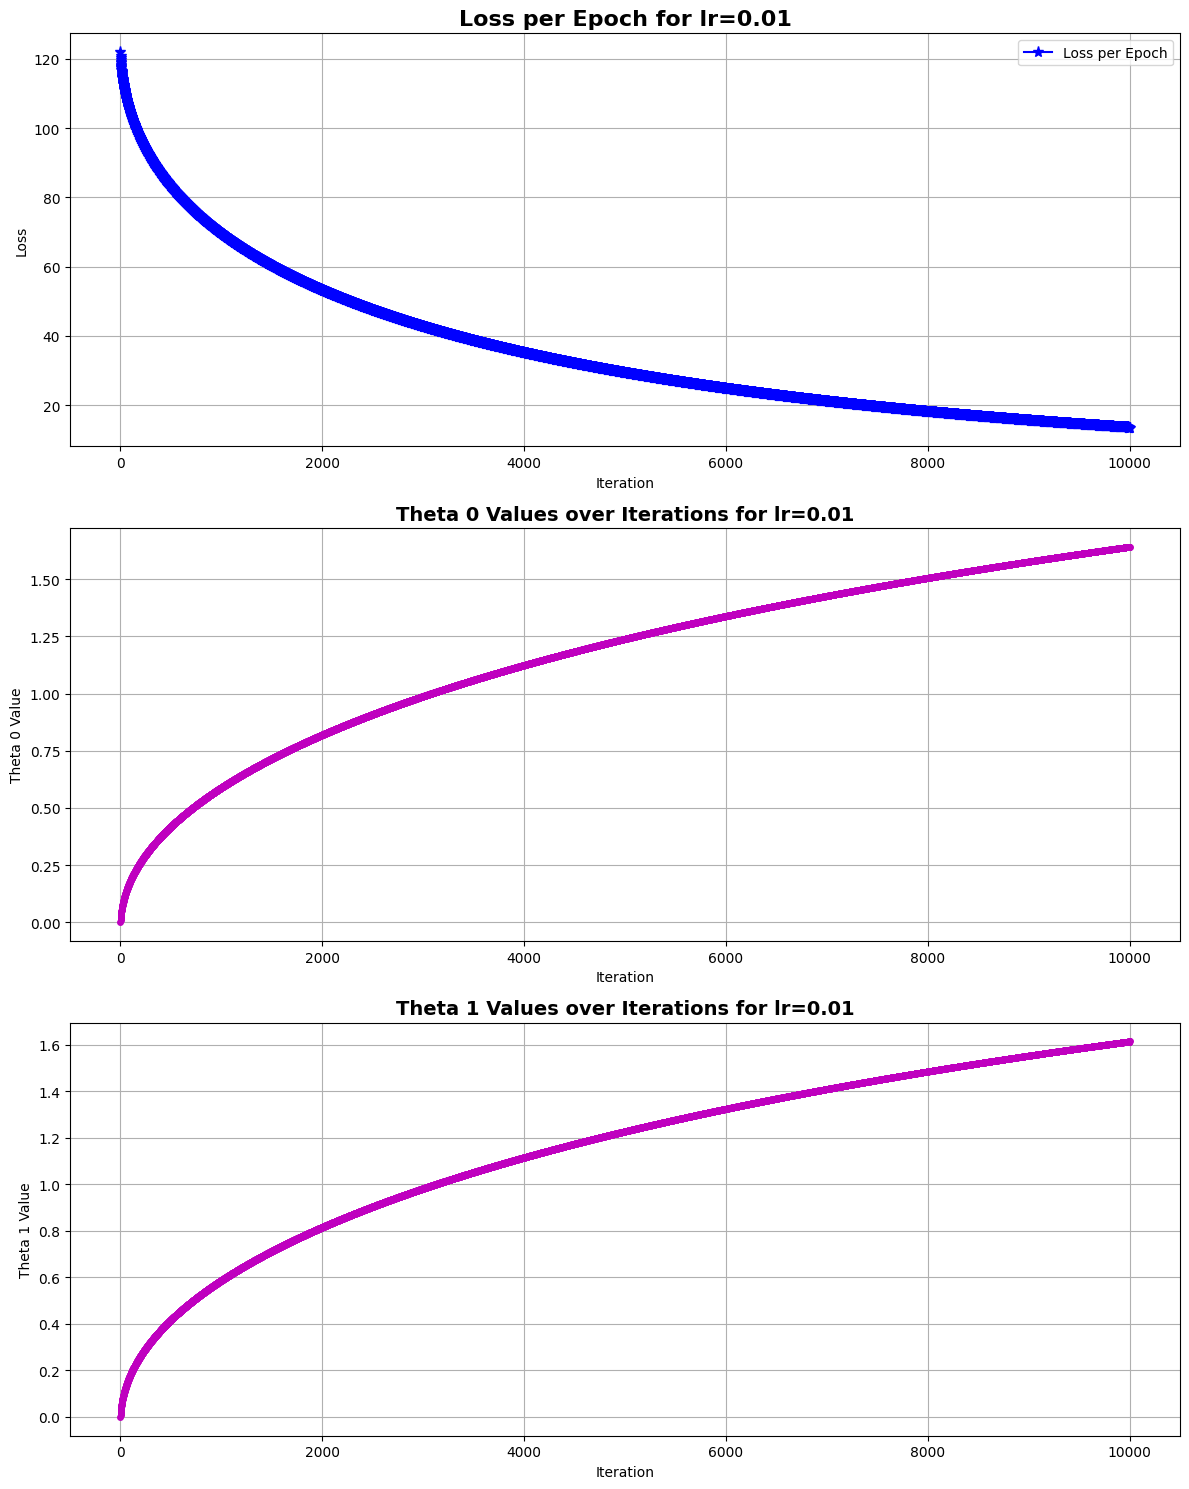

In [ ]:
# Initialize hyperparameters
lr = 0.01

# Run Adagrad
_, weights_history, cost_history, r2 = Adagrad_python(X, y, learning_rate=lr)

# Plot results
plot_results(weights_history, cost_history, lr=lr)

#### Use Large Learning Rate

Epoch [239/10000] - Loss: 0.541310 - r2: 0.970 - Weights: [3.92231119 2.13092538]:   2%|▌                        | 239/10000 [00:00<00:26, 373.28it/s]


Convergence reached at epoch 239.
                     Final Training Report
🟢 Total Epochs Run : 239
🟢 Final MSE        : 0.541
🟢 Final R-square   : 0.970
🟢 Final Weights    : [3.9223 2.1309]
Time taken for wrapper: 0.6443 seconds


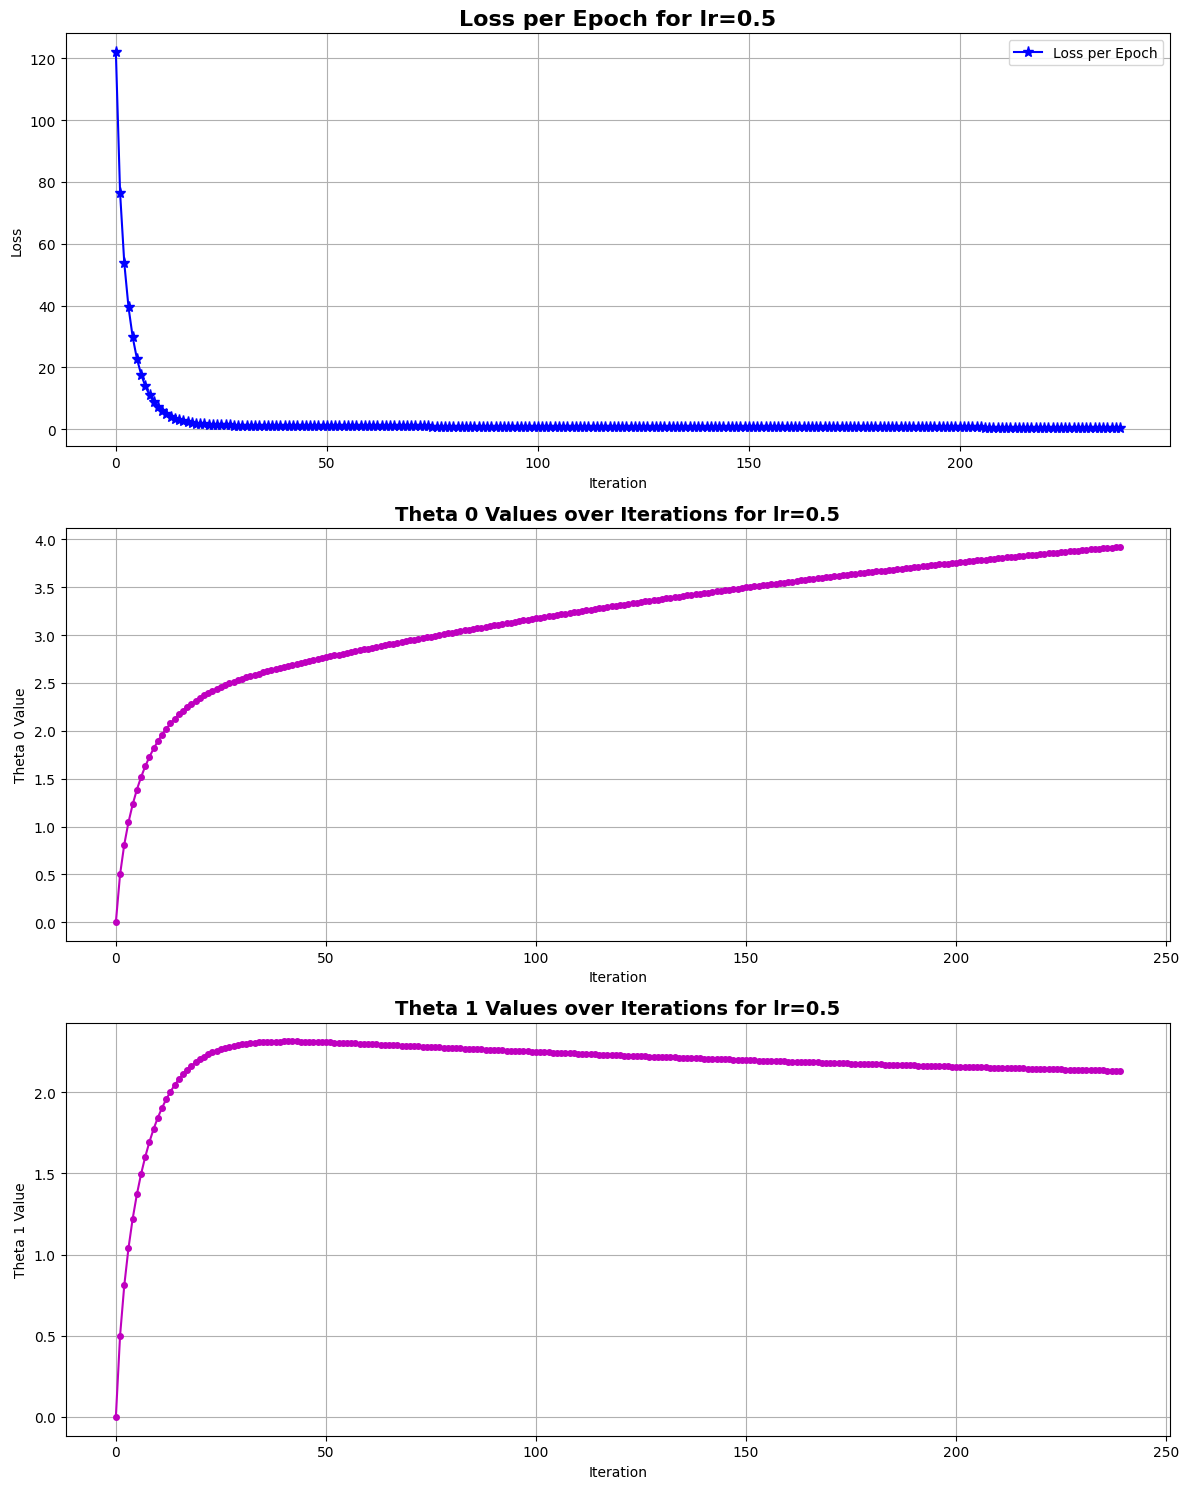

In [ ]:
lr = 0.5

# Run Adagrad
_, weights_history, cost_history, r2 = Adagrad_python(X, y, learning_rate=lr)

# Plot results
plot_results(weights_history, cost_history, lr=lr)

## 3. Adagrad Using PyTorch

The `Adagrad_torch` function implements the Adaptive Gradient (Adagrad) optimization algorithm using **PyTorch** to optimize the parameters (weights) of a linear regression model.

**Key Changes from the Python Code:**
1. **Data Conversion**: The input data `X` and `y` are converted to PyTorch tensors.
2. **Bias Term**: The bias term is added to create a column of ones.
3. **Gradient & Accumulation Calculation**: The gradient and running sum of squared gradients `G` are calculated using PyTorch tensor operations (`torch.sqrt`).
4. **Loss Calculation**: Losses are appended as Python floats using `loss.item()`.
5. **Weights Update**: The weights are updated using tensor operations and tracked in `weights_history`.

### Implementing Adagrad Using PyTorch

In [ ]:
@time_decorator
@report_decorator
def Adagrad_torch(X, y, **hyperparams):

    np.random.seed(42)
    torch.manual_seed(42)

    # Extract hyperparameters or set default values
    learning_rate = hyperparams.get('learning_rate', 0.01)
    epochs = hyperparams.get('epochs', 10_000)
    tolerance = hyperparams.get('tolerance', 0.001)
    epsilon = hyperparams.get('epsilon', 1e-8)

    X = np.insert(X, 0, 1, axis=1)
    y = y.reshape(-1, 1)
    m, n = X.shape                                      # Number of training examples and features

    # Convert data to PyTorch Tensors
    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    cost_history = []                                   # store all losses per iteration
    weights_history = []                                # store all weights per iteration

    theta = torch.zeros((n, 1), dtype=torch.float32)    # Initialize theta with zeros
    G = torch.zeros((n, 1), dtype=torch.float32)        # Initialize accumulated squared gradients with zeros
    weights_history.append(theta.clone().detach().numpy())

    # Progress bar for visual feedback
    pbar = tqdm(total=epochs, colour='green', ncols=150, bar_format=pbar_format)

    for epoch in range(epochs):

        # 1. Predict output using current theta (weights)
        h_x = X_tensor @ theta

        # 2. Calculate Error for all instances
        e = (h_x - y_tensor)
        loss = torch.sum(e ** 2) / (2 * m)              # Mean Squared Error (MSE) as loss
        cost_history.append(loss.item())

        # 3. Calculate gradient
        gradient = (X_tensor.T @ e) / m

        # 4. Accumulate squared gradients and update weights
        G = G + (gradient ** 2)
        theta = theta - (learning_rate / (torch.sqrt(G) + epsilon)) * gradient
        weights_history.append(theta.clone().detach().numpy())

        # optional Calculate r2 Score
        r2 = evaluate_model(X, y, theta.detach().numpy())

        # Print progress
        pbar.set_description(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss.item():.6f} - r2: {r2:.3f} - Weights: {theta.detach().numpy().flatten()}")
        pbar.update(1)

        # Early stopping for convergence
        if epoch > 0:
            if abs(cost_history[-1] - cost_history[-2]) < tolerance:
                print(f"Convergence reached at epoch {epoch + 1}.")
                break

    pbar.close()

    return epoch, weights_history, cost_history, r2

#### Use Small Learning Rate

Epoch [10000/10000] - Loss: 13.494458 - r2: 0.251 - Weights: [1.6421276 1.6150645]: 100%|██████████████████████| 10000/10000 [00:29<00:00, 333.62it/s]


                     Final Training Report
🟢 Total Epochs Run : 10000
🟢 Final MSE        : 13.494
🟢 Final R-square   : 0.251
🟢 Final Weights    : [1.6421 1.6151]
Time taken for wrapper: 30.0570 seconds


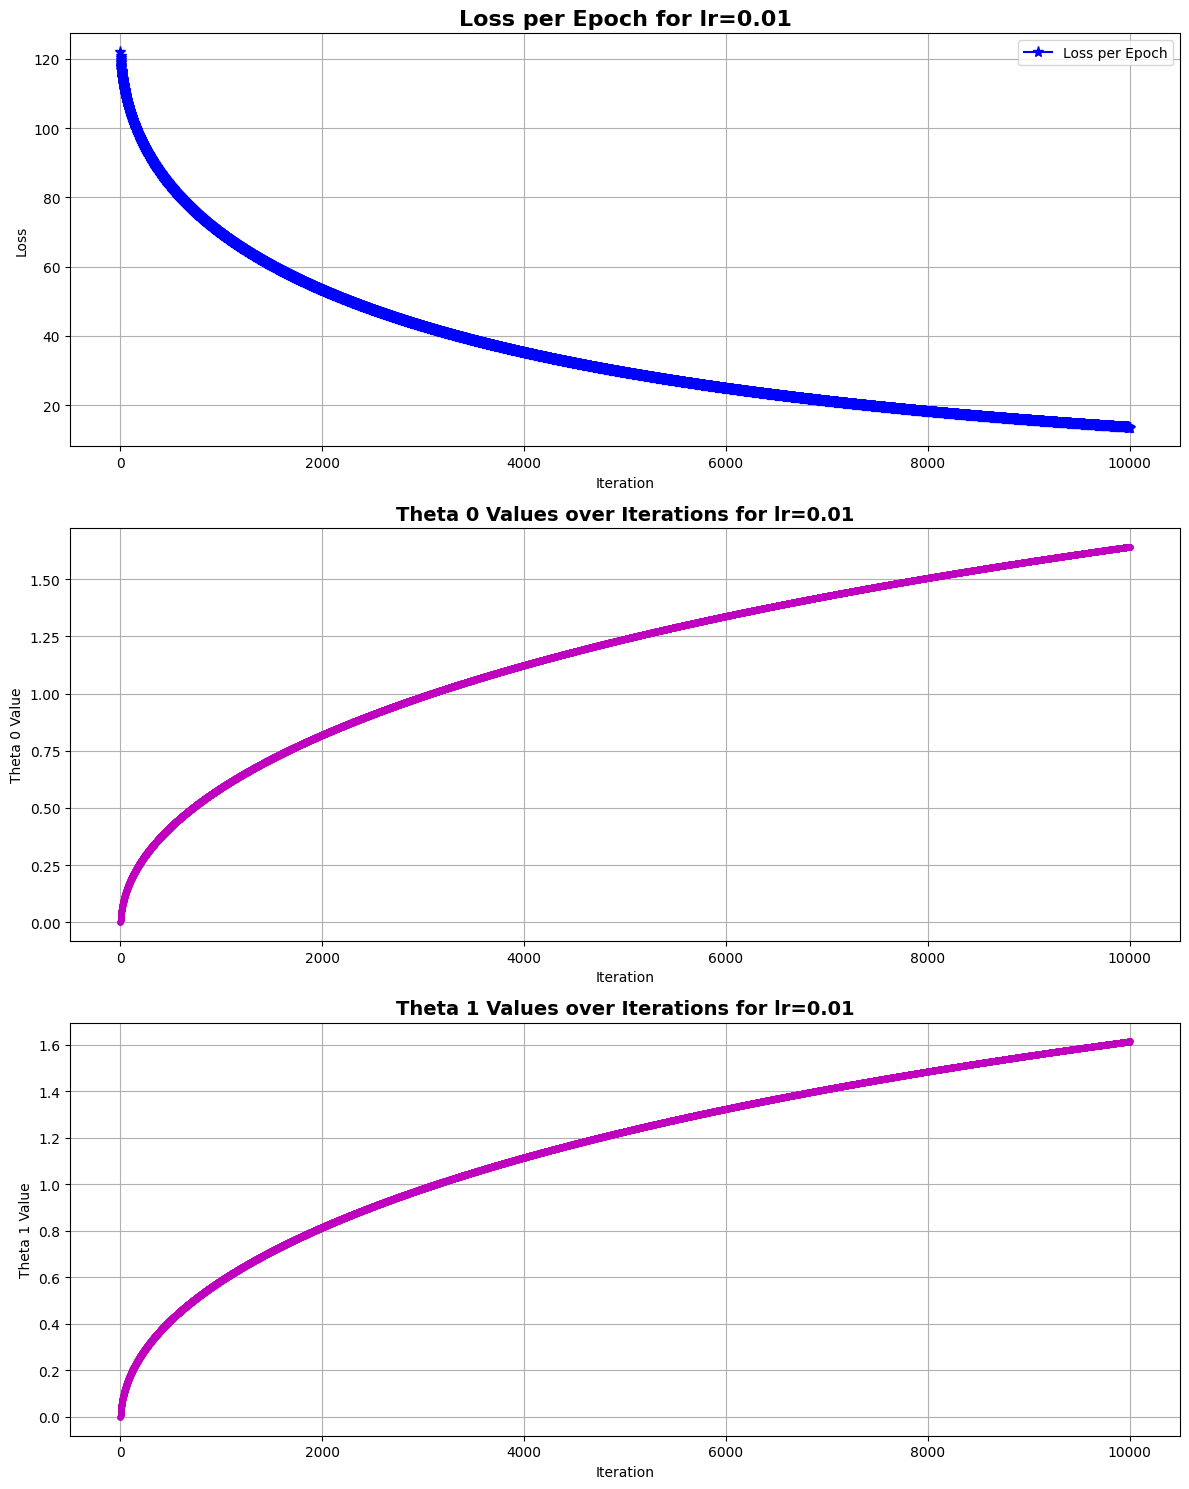

In [ ]:
lr = 0.01

# Run Adagrad in PyTorch
_, weights_history, cost_history, r2 = Adagrad_torch(X, y, learning_rate=lr)

# Plot results
plot_results(weights_history, cost_history, lr=lr)

#### Use Large Learning Rate

Epoch [239/10000] - Loss: 0.541310 - r2: 0.970 - Weights: [3.9223104 2.1309254]:   2%|▋                          | 239/10000 [00:00<00:30, 321.30it/s]


Convergence reached at epoch 239.
                     Final Training Report
🟢 Total Epochs Run : 239
🟢 Final MSE        : 0.541
🟢 Final R-square   : 0.970
🟢 Final Weights    : [3.9223 2.1309]
Time taken for wrapper: 0.7552 seconds


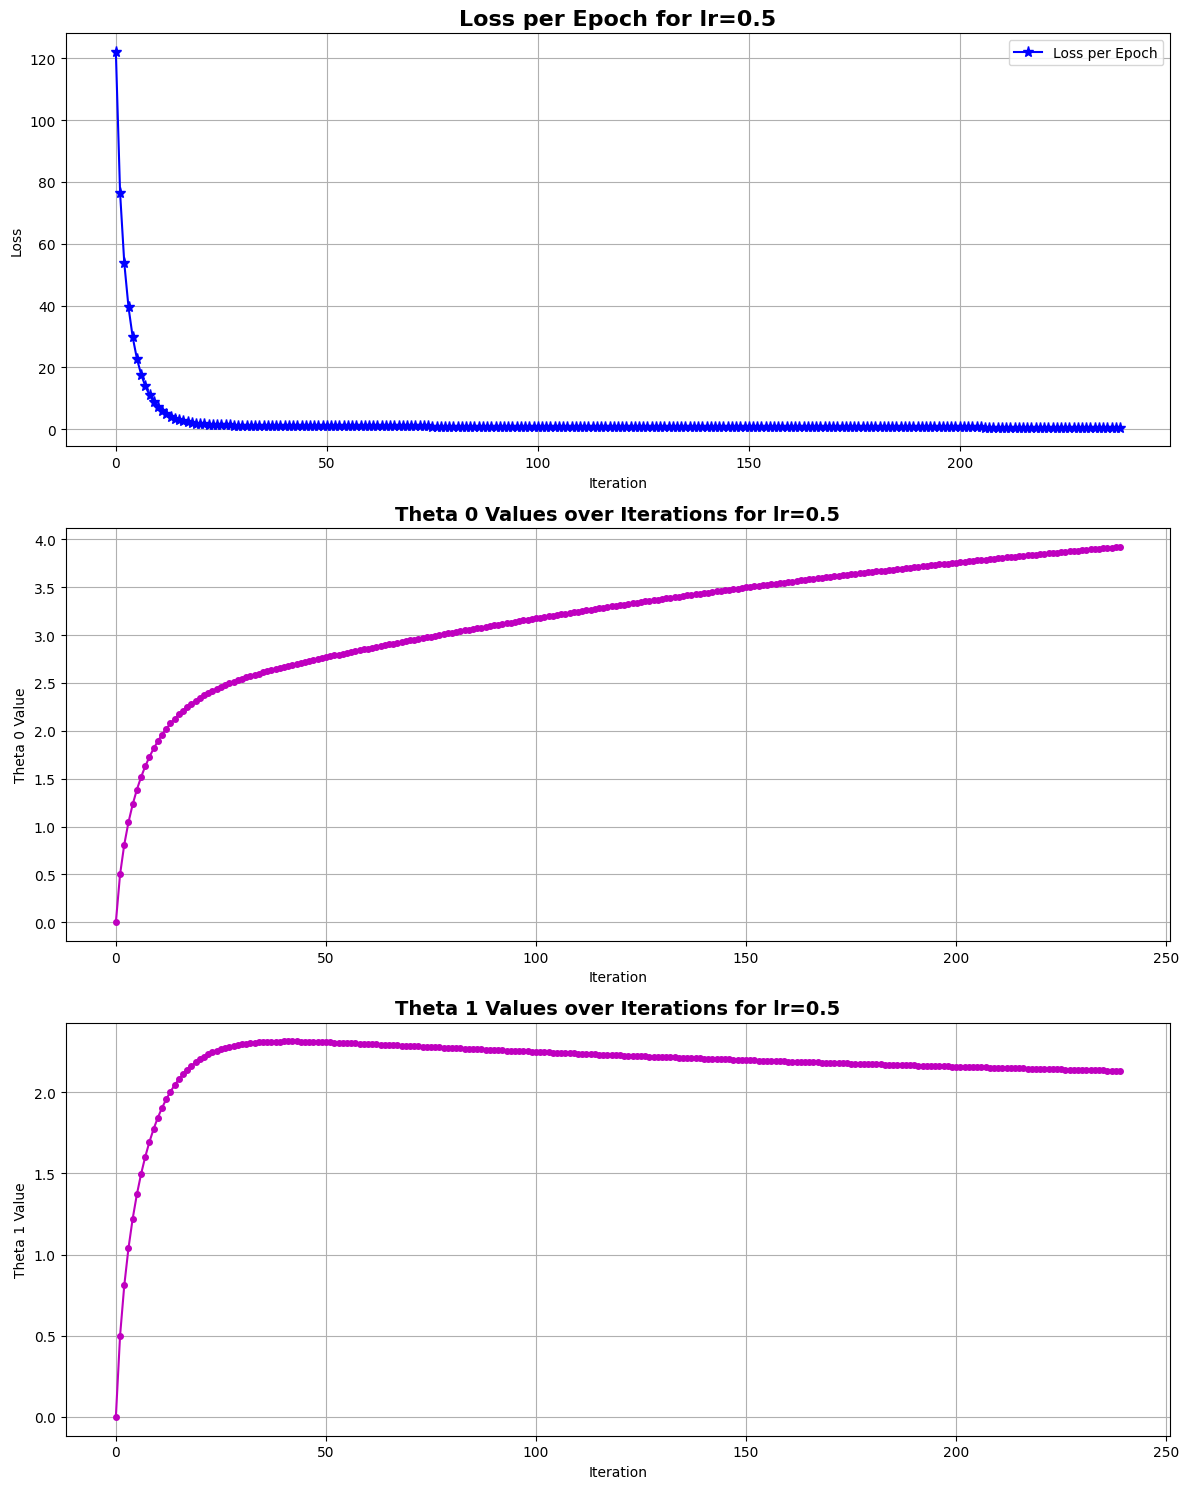

In [ ]:
lr = 0.5

# Run Adagrad in PyTorch
_, weights_history, cost_history, r2 = Adagrad_torch(X, y, learning_rate=lr)

# Plot results
plot_results(weights_history, cost_history, lr=lr)